# Guía de pandas para aprendizaje automático

Este cuaderno explica las operaciones de pandas usadas en las prácticas de regresión lineal. No se requiere formación estadística previa. Un **DataFrame** es una hoja de cálculo dentro de Python: las filas son casos y las columnas son campos.

**Cómo usar esta guía**
1. Lea la descripción breve de la función.
2. Ejecute la celda de ejemplo.
3. Complete la celda de práctica vacía con una idea similar, usando otra columna u otro filtro.

La tabla de ejemplo describe **pedidos semanales de clientes** en una empresa pequeña. Cualquier rol puede leerla: ventas, operaciones, soporte o análisis.

| Columna | Significado |
|---|---|
| `order_id` | Identificador único del pedido |
| `team` | Equipo que gestionó el pedido: Sales, Support u Operations |
| `channel` | Canal de llegada: Web, Store o Phone |
| `quantity` | Número de artículos |
| `unit_price` | Precio de un artículo |
| `delivery_days` | Días desde la compra hasta la entrega |
| `satisfaction` | Puntuación del cliente, de 1 a 10 |

En aprendizaje automático suele elegirse una columna **objetivo** para predecir (aquí, `satisfaction`) y el resto se usan como **características**. Pandas prepara la tabla antes de entrenar cualquier modelo.


## 0. Cargar pandas y crear una tabla

`import pandas as pd` carga la librería. El alias `pd` es el nombre corto habitual.

`pd.DataFrame({...})` construye una tabla a partir de un diccionario: cada clave se convierte en nombre de columna y cada lista en los valores de esa columna.

`pd.set_option(...)` solo cambia cómo se muestran los números; no modifica los datos.

`to_csv` escribe la tabla en un archivo. `read_csv` es la forma habitual de cargar datos en un proyecto de aprendizaje automático.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
plt.style.use("seaborn-v0_8-whitegrid")

df = pd.DataFrame({
    "order_id": [f"ORD-{i:03d}" for i in range(1, 13)],
    "team": [
        "Sales", "Support", "Operations", "Sales", "Support", "Sales",
        "Operations", "Support", "Sales", "Operations", "Support", "Sales",
    ],
    "channel": [
        "Web", "Phone", "Store", "Web", "Web", "Phone",
        "Store", "Phone", "Web", "Web", "Store", "Phone",
    ],
    "quantity": [2, 1, 5, 3, 2, 4, 1, 2, 6, 3, 1, 2],
    "unit_price": [19.5, 45.0, 12.0, 22.0, 18.0, 30.0, 55.0, 16.5, 10.0, 24.0, 40.0, 28.0],
    "delivery_days": [3, 7, 2, 4, 5, 6, 1, 8, 3, 4, 9, 2],
    "satisfaction": [8, 6, 9, 7, 5, 8, 9, 4, 8, 7, 3, 8],
})

# Problemas de calidad intencionados para las secciones de limpieza.
df.loc[3, "delivery_days"] = np.nan
df.loc[10, "unit_price"] = 400.0
df = pd.concat([df, df.iloc[[1]]], ignore_index=True)

df.to_csv("sample_orders.csv", index=False)
print("Filas y columnas:", df.shape)
df.head()


Filas y columnas: (13, 7)


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9
3,ORD-004,Sales,Web,3,22.00,NaN,7
4,ORD-005,Support,Web,2,18.00,5.00,5


In [2]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Cargue sample_orders.csv con pd.read_csv e imprima su shape.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 1. Inspeccionar la tabla: `head`, `tail`, `shape`, `columns`, `dtypes`

Estas funciones responden: *¿cómo luce la tabla?*

- `head(n)` — primeras n filas (5 por defecto). Úsela antes de cualquier análisis.
- `tail(n)` — últimas n filas.
- `shape` — tupla `(filas, columnas)`. Una tupla no se edita por accidente.
- `columns` — nombres de los campos.
- `dtypes` — tipo de cada columna (`int64`, `float64`, `object` para texto).

Los modelos de aprendizaje automático necesitan características numéricas. `dtypes` indica qué columnas ya son números y cuáles son texto.


In [3]:
print("Primeras filas")
display(df.head())

print("Últimas filas")
display(df.tail(3))

print("shape (filas, columnas):", df.shape)
print("nombres de columnas:", list(df.columns))
print("tipos de dato")
display(df.dtypes.to_frame("dtype"))


Primeras filas


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9
3,ORD-004,Sales,Web,3,22.00,NaN,7
4,ORD-005,Support,Web,2,18.00,5.00,5


Últimas filas


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
10,ORD-011,Support,Store,1,400.00,9.00,3
11,ORD-012,Sales,Phone,2,28.00,2.00,8
12,ORD-002,Support,Phone,1,45.00,7.00,6


shape (filas, columnas): (13, 7)
nombres de columnas: ['order_id', 'team', 'channel', 'quantity', 'unit_price', 'delivery_days', 'satisfaction']
tipos de dato


,dtype
order_id,object
team,object
channel,object
quantity,int64
unit_price,float64
delivery_days,float64
satisfaction,int64


In [4]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Muestre solo las primeras 4 filas y luego liste los nombres de columna como una lista de Python.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 2. Seleccionar columnas: `[]` y `loc`

Rara vez se necesitan todas las columnas a la vez.

- `df["satisfaction"]` — una columna. El resultado es una **Series** (una lista con índice).
- `df[["team", "satisfaction"]]` — varias columnas. Se pasa una **lista**. El resultado sigue siendo un DataFrame.
- `df.loc[:, ["team", "satisfaction"]]` — la misma idea con `loc`. La primera posición son las filas (`:` significa todas) y la segunda, las columnas.

En los cuadernos anteriores los nombres se guardaban en una **tupla** para fijar la lista de características; después se convertía con `list(...)` porque pandas espera una lista cuando hay varias columnas.


In [5]:
# Una columna -> Series
satisfaction = df["satisfaction"]
print("Tipo de una columna:", type(satisfaction))
display(satisfaction.head())

# Varias columnas a partir de una tupla de nombres
feature_tuple = ("quantity", "unit_price", "delivery_days")
features = df.loc[:, list(feature_tuple)]
display(features.head())


Tipo de una columna: <class 'pandas.core.series.Series'>


0    8
1    6
2    9
3    7
4    5
Name: satisfaction, dtype: int64

,quantity,unit_price,delivery_days
0,2,19.50,3.00
1,1,45.00,7.00
2,5,12.00,2.00
3,3,22.00,NaN
4,2,18.00,5.00


In [6]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Seleccione channel y satisfaction con loc. Guarde primero los nombres en una tupla.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 3. Filtrar filas: máscaras booleanas, `&`, `between`, `query`

Un **filtro** conserva solo las filas que cumplen una condición. Así se estudia un subgrupo antes de entrenar un modelo.

- `df["satisfaction"] >= 8` produce True/False en cada fila (una máscara).
- `df[mask]` conserva las filas True.
- Combine condiciones con `&` (y) y `|` (o). Cada condición debe ir entre paréntesis.
- `between(low, high)` comprueba un intervalo numérico inclusivo.
- `query("satisfaction >= 8")` expresa la misma idea en un texto breve.

Un filtro **no** demuestra que un campo cause otro. Solo describe un subconjunto.


In [7]:
high_score = df[df["satisfaction"] >= 8]
print("Pedidos con satisfaction >= 8:", len(high_score))

web_and_fast = df[(df["channel"] == "Web") & (df["delivery_days"] <= 4)]
print("Pedidos Web entregados en 4 días o menos:", len(web_and_fast))

typical_price = df[df["unit_price"].between(10, 50)]
print("Pedidos con un precio unitario habitual:", len(typical_price))

same_with_query = df.query("channel == 'Web' and satisfaction >= 7")
display(same_with_query[["order_id", "channel", "satisfaction"]])


Pedidos con satisfaction >= 8: 6
Pedidos Web entregados en 4 días o menos: 3
Pedidos con un precio unitario habitual: 11


,order_id,channel,satisfaction
0,ORD-001,Web,8
3,ORD-004,Web,7
8,ORD-009,Web,8
9,ORD-010,Web,7


In [8]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Filtre los pedidos del equipo Support con satisfaction menor que 6. Después reescriba el mismo filtro con query.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 4. Agrupar resultados: `groupby` y `agg`

`groupby("team")` divide la tabla por categoría. `agg(...)` calcula un resumen dentro de cada grupo.

En aprendizaje automático sirve para ver si el objetivo se comporta de forma distinta entre grupos (por ejemplo, satisfacción según el canal). El tamaño de los grupos importa: una media con 2 filas es menos estable que una media con 40 filas.


In [9]:
by_team = df.groupby("team").agg(
    n_orders=("order_id", "count"),
    average_satisfaction=("satisfaction", "mean"),
    median_delivery=("delivery_days", "median"),
).sort_values("average_satisfaction", ascending=False)

by_team


,n_orders,average_satisfaction,median_delivery
team,,,
Operations,3,8.33,2.00
Sales,5,7.80,3.00
Support,5,4.80,7.00


In [10]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Agrupe por channel. Para cada canal muestre el número de pedidos y la media de unit_price.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 5. Detectar datos incompletos: `isna` y `dropna`

`NaN` significa “not a number”: el valor está ausente.

- `df.isna()` — True donde la celda falta.
- `df.isna().sum()` — recuento de ausencias por columna.
- `dropna()` — elimina filas con al menos un valor ausente.

Los valores ausentes impiden ejecutar la mayoría de las funciones de regresión lineal. Hay que eliminar esas filas o imputarlas. En un curso inicial, eliminar unas pocas filas incompletas es aceptable si se documenta la decisión.


In [11]:
print("Valores ausentes por columna")
display(df.isna().sum().to_frame("missing"))

print("Filas con al menos un valor ausente")
display(df[df.isna().any(axis=1)])


Valores ausentes por columna


,missing
order_id,0
team,0
channel,0
quantity,0
unit_price,0
delivery_days,1
satisfaction,0


Filas con al menos un valor ausente


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
3,ORD-004,Sales,Web,3,22.00,NaN,7


In [12]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Cuente los valores ausentes solo en delivery_days. Luego cree una copia sin filas incompletas con dropna().
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 6. Detectar filas repetidas: `duplicated` y `drop_duplicates`

Un duplicado es una fila que aparece más de una vez. Los duplicados inflan los recuentos y pueden sesgar un modelo hacia ese caso repetido.

- `duplicated().sum()` — cuántas copias extra existen (la primera no se cuenta).
- `drop_duplicates()` — conserva una copia de cada fila única.


In [13]:
print("Filas duplicadas extra:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])


Filas duplicadas extra: 1


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
1,ORD-002,Support,Phone,1,45.00,7.00,6
12,ORD-002,Support,Phone,1,45.00,7.00,6


In [14]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Cree clean_no_dup eliminando duplicados. Imprima el número de filas antes y después.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 7. Detectar valores fuera de rango: `between` y máscaras

En el cuaderno de diseño gráfico, las puntuaciones debían permanecer entre 1 y 10. Aquí, `unit_price` debe ser un importe realista y `satisfaction` debe estar entre 1 y 10.

`~` significa “no”. `~series.between(a, b)` señala los valores fuera del intervalo.

Los valores fuera de rango abren huecos en los gráficos y pueden arrastrar la recta de regresión hacia un punto extremo. Elimínelos solo cuando exista una regla clara (por ejemplo: “el precio no puede ser 400 en este catálogo”).


In [15]:
price_ok = df["unit_price"].between(1, 100)
score_ok = df["satisfaction"].between(1, 10)
invalid = df[~price_ok | ~score_ok]
print("Filas fuera del rango acordado")
display(invalid)


Filas fuera del rango acordado


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
10,ORD-011,Support,Store,1,400.00,9.00,3


In [16]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Marque las filas donde delivery_days no esté entre 1 y 10. Muestre esas filas.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 8. Construir una copia limpia: `copy`, `drop_duplicates`, `dropna`, `reset_index`

No sobrescriba el `df` original hasta haber inspeccionado los problemas. `.copy()` crea una tabla independiente.

`reset_index(drop=True)` reconstruye los números de fila 0, 1, 2, ... después de borrar registros. Así se evitan huecos en el índice.


In [17]:
# copy() deja el df original sin cambios.
clean_df = df.drop_duplicates().dropna().copy()
clean_df = clean_df[clean_df["unit_price"].between(1, 100)].copy()
clean_df = clean_df.reset_index(drop=True)

print("Filas originales:", len(df))
print("Filas limpias:", len(clean_df))
clean_df


Filas originales:

 13
Filas limpias: 10


,order_id,team,channel,quantity,unit_price,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9
3,ORD-005,Support,Web,2,18.00,5.00,5
4,ORD-006,Sales,Phone,4,30.00,6.00,8
5,ORD-007,Operations,Store,1,55.00,1.00,9
6,ORD-008,Support,Phone,2,16.50,8.00,4
7,ORD-009,Sales,Web,6,10.00,3.00,8
8,ORD-010,Operations,Web,3,24.00,4.00,7
9,ORD-012,Sales,Phone,2,28.00,2.00,8


In [18]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# A partir de df, cree su propio clean_df: elimine duplicados, elimine ausencias, conserve unit_price entre 1 y 100 y luego reset_index.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 9. Números resumen: `describe`, `min`, `max`, `mean`, `median`, `std`

Estos son los estadísticos descriptivos básicos usados antes de un modelo:

- **min / max** — recorrido observado.
- **mean** — promedio aritmético; sensible a valores extremos.
- **median** — valor central tras ordenar; más resistente a extremos.
- **std** — dispersión de los números respecto de la media.
- **count** — cuántos valores no ausentes se usaron.

`describe()` los calcula juntos. `.T` transpone la tabla para que cada variable sea una fila, más fácil de leer.


In [19]:
numeric_columns = ["quantity", "unit_price", "delivery_days", "satisfaction"]
summary = clean_df[numeric_columns].describe().T
summary = summary.rename(columns={
    "count": "n",
    "mean": "mean",
    "std": "std_dev",
    "min": "min",
    "25%": "Q1",
    "50%": "median",
    "75%": "Q3",
    "max": "max",
})
summary["range"] = summary["max"] - summary["min"]
summary


,n,mean,std_dev,min,Q1,median,Q3,max,range
quantity,10.00,2.80,1.69,1.00,2.00,2.00,3.75,6.00,5.00
unit_price,10.00,25.80,14.43,10.00,16.88,21.75,29.50,55.00,45.00
delivery_days,10.00,4.10,2.33,1.00,2.25,3.50,5.75,8.00,7.00
satisfaction,10.00,7.20,1.69,4.00,6.25,8.00,8.00,9.00,5.00


In [20]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Calcule media, mínimo y máximo de satisfaction en clean_df sin usar describe(). Puede usar clean_df['satisfaction'].mean().
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 10. Renombrar columnas: `rename`

`rename(columns={old: new})` cambia las etiquetas. Unos nombres claros importan cuando más adelante se escribe `df["satisfaction"]` en un modelo.

Úselo después de `describe()` si desea etiquetas como `median` en lugar de `50%`.


In [21]:
renamed = clean_df.rename(columns={"unit_price": "price_per_item"})
print(list(renamed.columns))
renamed.head(3)


['order_id', 'team', 'channel', 'quantity', 'price_per_item', 'delivery_days', 'satisfaction']


,order_id,team,channel,quantity,price_per_item,delivery_days,satisfaction
0,ORD-001,Sales,Web,2,19.50,3.00,8
1,ORD-002,Support,Phone,1,45.00,7.00,6
2,ORD-003,Operations,Store,5,12.00,2.00,9


In [22]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Renombre satisfaction a customer_score en una copia. No sobrescriba clean_df.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 11. Correlación: `corr`

`corr()` mide la asociación **lineal** entre columnas numéricas, de −1 a 1.

- Cerca de +1: ambas tienden a aumentar juntas.
- Cerca de −1: una tiende a bajar cuando la otra sube.
- Cerca de 0: no hay una relación en línea recta clara.

La correlación no es causalidad. Es una primera pista de qué característica usar en una regresión lineal simple.


In [23]:
correlations = clean_df[numeric_columns].corr()
display(correlations)

with_target = correlations["satisfaction"].drop("satisfaction")
with_target.sort_values(key=abs, ascending=False).to_frame("correlation_with_satisfaction")


,quantity,unit_price,delivery_days,satisfaction
quantity,1.00,-0.67,-0.19,0.37
unit_price,-0.67,1.00,-0.07,0.18
delivery_days,-0.19,-0.07,1.00,-0.83
satisfaction,0.37,0.18,-0.83,1.00


,correlation_with_satisfaction
delivery_days,-0.83
quantity,0.37
unit_price,0.18


In [24]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# ¿Qué columna numérica tiene la mayor correlación absoluta con satisfaction? Guarde su nombre en most_related.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 12. Cortar una columna numérica en grupos: `pd.cut`

`pd.cut(series, bins=3, labels=...)` convierte un número en grupos Bajo / Medio / Alto. Después, `groupby` puede comparar el objetivo entre esos grupos.

Es la misma idea que filtrar, pero los grupos se crean a partir de una escala numérica y no de una categoría que ya existía.


In [25]:
clean_df = clean_df.copy()
clean_df["delivery_group"] = pd.cut(
    clean_df["delivery_days"],
    bins=3,
    labels=["fast", "medium", "slow"],
)
clean_df.groupby("delivery_group", observed=True).agg(
    n=("order_id", "count"),
    average_satisfaction=("satisfaction", "mean"),
)


,n,average_satisfaction
delivery_group,,
fast,5,8.40
medium,2,6.00
slow,3,6.00


In [26]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Cree tres grupos para quantity con pd.cut y compare la satisfaction media en cada grupo.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 13. Combinar tablas: `pd.concat`

`pd.concat([table_a, table_b], ignore_index=True)` apila filas. El cuaderno de diseño gráfico usó esto para insertar un duplicado a propósito.

`ignore_index=True` reconstruye los números de fila. Sin él, dos tablas pueden compartir los mismos valores de índice.


In [27]:
extra_row = clean_df.iloc[[0]]
stacked = pd.concat([clean_df.head(2), extra_row], ignore_index=True)
stacked[["order_id", "team", "satisfaction"]]


,order_id,team,satisfaction
0,ORD-001,Sales,8
1,ORD-002,Support,6
2,ORD-001,Sales,8


In [28]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Concatene las tres primeras filas de clean_df con la última. Use ignore_index=True.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 14. Aplicar una función a cada columna: `apply`

`apply(function, axis=0)` ejecuta una función en cada columna (axis=0) o en cada fila (axis=1).

En los cuadernos anteriores se usó:

```python
df[score_columns].apply(lambda column: column.between(1, 10)).all(axis=1)
```

Eso significa: para cada columna de puntuación, comprobar si los valores están entre 1 y 10; después exigir que **todas** esas comprobaciones sean True en la misma fila.


In [29]:
score_like = ["quantity", "delivery_days", "satisfaction"]
in_range = clean_df[score_like].apply(lambda column: column.between(0, 10))
print("Comprobación de rango por columna")
display(in_range.head())
print("Filas en las que todas las columnas revisadas están en rango:", in_range.all(axis=1).sum())


Comprobación de rango por columna


,quantity,delivery_days,satisfaction
0,True,True,True
1,True,True,True
2,True,True,True
3,True,True,True
4,True,True,True


Filas en las que todas las columnas revisadas están en rango: 10


In [30]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Use apply para comprobar si quantity, delivery_days y satisfaction son todas >= 1 en cada fila.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 15. Gráficos usados antes de modelar: histograma y dispersión

Un **histograma** (`hist`) muestra cómo se distribuyen los valores. Un **diagrama de dispersión** (`scatter`) muestra una variable frente a otra. La línea roja de `np.polyfit` es un bosquejo rápido de recta, todavía no el modelo entrenado.

`plt.subplots` crea varios gráficos en una cuadrícula. `zip(axes.flat, columns)` asigna una columna a cada panel.


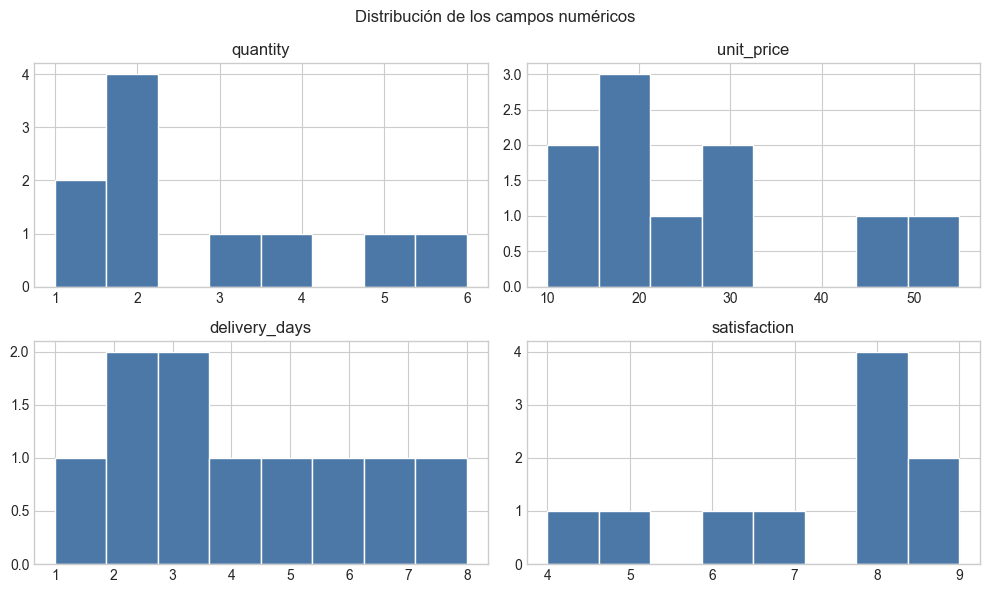

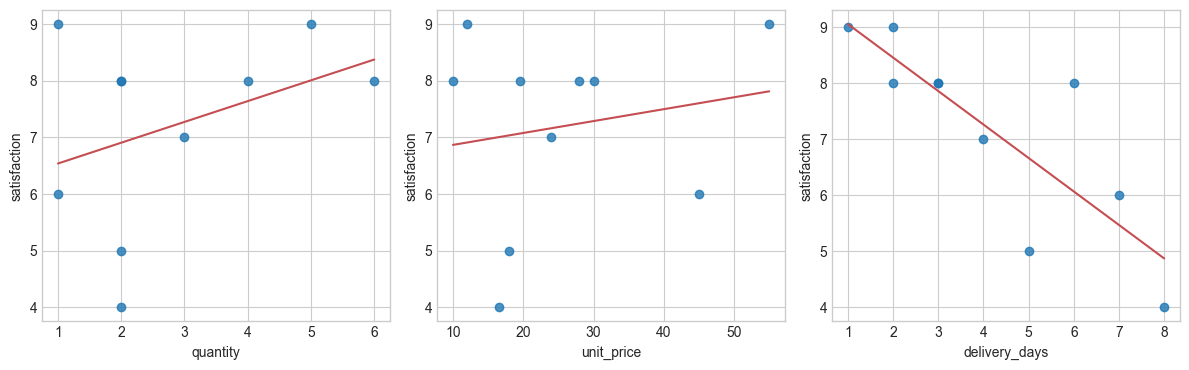

In [31]:
clean_df[numeric_columns].hist(figsize=(10, 6), bins=8, color="#4C78A8", edgecolor="white")
plt.suptitle("Distribución de los campos numéricos")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, column in zip(axes, ["quantity", "unit_price", "delivery_days"]):
    ax.scatter(clean_df[column], clean_df["satisfaction"], alpha=0.8)
    slope, intercept = np.polyfit(clean_df[column], clean_df["satisfaction"], 1)
    x_line = np.linspace(clean_df[column].min(), clean_df[column].max(), 50)
    ax.plot(x_line, intercept + slope * x_line, color="#C44E52")
    ax.set_xlabel(column)
    ax.set_ylabel("satisfaction")
plt.tight_layout()
plt.show()


In [32]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Dibuje un diagrama de dispersión de delivery_days (X) frente a satisfaction (Y). Añada etiquetas de ejes.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 16. De una tabla limpia a un modelo simple (scikit-learn)

Después de que pandas ha preparado la tabla, scikit-learn puede estimar una recta.

- `train_test_split` reserva algunas filas para probar el modelo con datos que no usó al aprender.
- `LinearRegression().fit(X, y)` estima el intercepto y la pendiente.
- `predict` produce los valores estimados del objetivo.
- `mean_absolute_error`, RMSE y `r2_score` miden qué tan cerca están esas estimaciones.

`X` debe ser un DataFrame de características. `y` es la Series objetivo. Por eso se escribe `clean_df[["delivery_days"]]` con doble corchete.


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

X = clean_df[["delivery_days"]]
y = clean_df["satisfaction"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"satisfaction ≈ {model.intercept_:.2f} + ({model.coef_[0]:.2f} × delivery_days)")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R2:", round(r2_score(y_test, y_pred), 3))


satisfaction ≈ 9.85 + (-0.65 × delivery_days)
MAE: 0.384
RMSE: 0.453
R2: 0.868


In [34]:
# CELDA DE PRÁCTICA — complete este ejercicio.
# Entrene el mismo LinearRegression usando unit_price en lugar de delivery_days. Imprima intercepto, pendiente y R2.
# Conserve las variables df / clean_df de las celdas anteriores. No sobrescriba df
# salvo que la pista pida crear una copia.


## 17. Mini diccionario de las funciones de los cuadernos anteriores

| Función | Uso habitual antes de un modelo |
|---|---|
| `read_csv` / `to_csv` | Cargar y guardar tablas |
| `head`, `shape`, `dtypes` | Primera inspección |
| `loc`, lista/tupla de nombres | Seleccionar características |
| máscara booleana, `&`, `query`, `between` | Estudiar subgrupos y rangos válidos |
| `groupby` + `agg` | Comparar el objetivo entre categorías |
| `isna`, `dropna` | Tratar filas incompletas |
| `duplicated`, `drop_duplicates` | Eliminar filas repetidas |
| `copy`, `reset_index` | Conservar una tabla limpia segura |
| `describe`, `mean`, `median`, `min`, `max`, `std` | Resumir escala y centro |
| `rename` | Aclarar nombres de columna |
| `corr` | Ordenar asociaciones lineales con el objetivo |
| `pd.cut` | Convertir un número en grupos |
| `pd.concat` | Apilar tablas |
| `apply` | Repetir una comprobación en varias columnas |
| `hist`, `scatter` | Ver distribuciones y relaciones |
| `train_test_split`, `LinearRegression` | Estimar y evaluar una recta |

Cuando vuelva a `graphic_post_impact_student.ipynb`, cada `TODO` corresponde a una de estas funciones.
